In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [2]:
def load_image_from_txt(filename, shape):
    # Read all numbers from the file
    with open(filename, 'r') as f:
        data_str = f.read()

    # Convert string to list of integers
    data_list = list(map(int, data_str.split()))

    # Convert to numpy array``
    img_array = np.array(data_list, dtype=np.uint8)

    # Reshape to (height, width) or (height, width, channels) as needed
    img_array = img_array.reshape(shape)

    return img_array

def load_data_from_txt(filename, shape):
    # Read all numbers from the file
    with open(filename, 'r') as f:
        data_str = f.read()

    # Convert string to list of integers
    data_list = list(map(float, data_str.split()))

    # Convert to numpy array
    img_array = np.array(data_list, dtype=np.float64)

    # Reshape to (height, width) or (height, width, channels) as needed
    img_array = img_array.reshape(shape)

    return img_array

In [3]:
BASE_IMG = "image_data.txt"
LAB_IMG = "lab_image_data.txt"

IMG_SHAPE = (240, 320, 3)  # Example shape, adjust as needed

LENNA_SHAPE = (512, 512)  # Shape of Lenna image
LENNA_RGB_SHAPE = (512, 512, 3)  # Shape of Lenna image

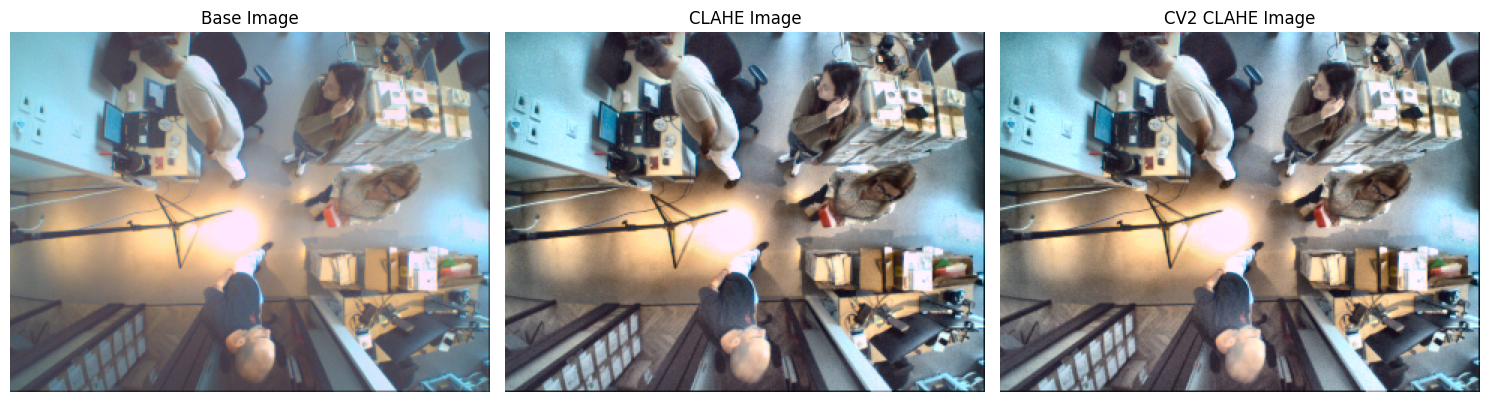

In [4]:
base_image = load_image_from_txt(BASE_IMG, IMG_SHAPE)
clahe_image = load_image_from_txt("output_data.txt", IMG_SHAPE)

original_img_lab = cv2.cvtColor(base_image, cv2.COLOR_RGB2LAB)
img_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
original_img_clahe = img_clahe.apply(original_img_lab[:, :, 0])

original_img_lab[:, :, 0] = original_img_clahe

original_img_rgb = cv2.cvtColor(original_img_lab, cv2.COLOR_LAB2RGB)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(base_image)
plt.title('Base Image')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(clahe_image)
plt.title('CLAHE Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(original_img_rgb)
plt.title('CV2 CLAHE Image')
plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
diff = np.abs(clahe_image.astype(int) - original_img_rgb)
diff.max(), diff.mean()

(21, 3.532890625)

In [6]:
cv2.imwrite("/home/klymy/projects/rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources/pg_object_detection/samples/img_320.bmp", cv2.cvtColor(clahe_image, cv2.COLOR_RGB2BGR))

cv2.imwrite("/home/klymy/projects/rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources/pg_object_detection/samples/img_32.bmp", cv2.cvtColor(cv2.resize(clahe_image, (32, 24)), cv2.COLOR_RGB2BGR))

True